# Lecture 12 – Text as data: counts, similarity, and topics

QSS 20 · Modern Statistical Computing · Fall 2026

Content credit: see the course
[Acknowledgements](https://kengchichang.github.io/QSS20/acknowledgements).

### Agenda

1. **Bag of words and the document-term matrix.** `CountVectorizer`.
2. **Cosine similarity between documents.** `cosine_similarity`.
3. **TF-IDF weights.** `TfidfVectorizer`.
4. **Topic models.** `NMF`, with a look at LDA and BERTopic.

Part 1 builds each idea on a toy corpus of three short documents. Part 2
runs the same steps on 85 real essays. Part 3 adds topic models.

### Setup: install once

This lecture adds one package: `scikit-learn`, Python's main library for
machine learning. Its import name is `sklearn`. Install it once, in a
terminal, not in this notebook:

```bash
conda activate qss20
conda install scikit-learn
```

- Lectures 13 and 14 use it too.
- If an import in the next cell still fails, restart the kernel
  (Kernel → Restart Kernel) and run it again.

### Setup: one thread for scikit-learn

Restart the kernel, then run this cell first, before any other import.

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'

- On computers with many cores, scikit-learn and NumPy can start so many
  threads that the kernel crashes. One thread is enough for these data.
- `os.environ` holds the settings that programs read when they start.
  `OMP_NUM_THREADS` sets how many threads the math libraries may use. It
  works only if NumPy has not been imported yet in this kernel.

### Setup: imports and folders

Load every package the lecture uses, and name the data folder.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Arc
from sklearn.decomposition import NMF, LatentDirichletAllocation
from sklearn.feature_extraction.text import (
    ENGLISH_STOP_WORDS, CountVectorizer, TfidfVectorizer)
from sklearn.metrics.pairwise import cosine_similarity

pd.set_option('display.max_rows', 20)
pd.set_option('display.max_colwidth', 100)

# Sharp figures on high-resolution screens, from lecture 6.
%config InlineBackend.figure_format = 'retina'
# Show only the last line of an error message.
%xmode Minimal

RAW = Path('../../data/raw')

Exception reporting mode: Minimal


- `sklearn.feature_extraction.text` turns text into matrices.
  `sklearn.metrics.pairwise` compares rows. `sklearn.decomposition` fits
  topic models. Each is linked at first use.

## Who wrote the disputed essays?

The 85 Federalist essays appeared in New York newspapers in 1787 and 1788,
signed "Publius", to argue for ratifying the Constitution. Three men wrote
them: Alexander Hamilton, James Madison, and John Jay. Decades later,
Hamilton and Madison each left a list of the essays they had written. The
lists disagree on 12 essays: 49 to 58, 62, and 63.

Historians argued about the 12 for more than a century. In 1963 two
statisticians, Frederick Mosteller and David Wallace, settled the question
by counting words. Today's lecture rebuilds that argument.

The essays are the text files of lectures 2 and 3 (`wc`, `grep`), from the
[Library of Congress](https://guides.loc.gov/federalist-papers/full-text).

In [3]:
fp51 = (RAW / 'federalist' / 'fp51.txt').read_text(encoding='utf-8')
print(fp51[:400])

TO WHAT expedient, then, shall we finally resort, for maintaining in 
        practice the necessary partition of power among the several departments, 
        as laid down in the Constitution? The only answer that can be given is, 
        that as all these exterior provisions are found to be inadequate, the 
        defect must be supplied, by so contriving the interior structure of the 
       


- One file per essay, `fp01.txt` to `fp85.txt`. The files have no title or
  author line; the number in the file name is the essay number.
- `encoding='utf-8'` names the file's character encoding, because Python on
  Windows assumes a different one.

### Read the 85 essays into a table

Loop over the essay numbers, read each file, and keep one row per essay.

In [4]:
rows = []
for n in range(1, 86):
    path = RAW / 'federalist' / f'fp{n:02d}.txt'
    rows.append({'essay': n,
                 'text': path.read_text(encoding='utf-8')})
essays = pd.DataFrame(rows)
essays

,essay,text
0,1,AFTER an unequivocal experience of the inefficiency of the subsisting \n federal governme...
1,2,"WHEN the people of America reflect that they are now called upon to decide \n a question,..."
2,3,"IT IS not a new observation that the people of any country (if, like \n the Americans, in..."
3,4,MY LAST paper assigned several reasons why the safety of the people would \n be best secu...
4,5,"QUEEN ANNE, in her letter of the 1st July, 1706, to the Scotch Parliament, \n makes some ..."
...,...,...
80,81,LET US now return to the partition of the judiciary authority between \n different courts...
81,82,"THE erection of a new government, whatever care or wisdom may distinguish \n the work, ca..."
82,83,"THE objection to the plan of the convention, which has met with most \n success in this S..."
83,84,"IN THE course of the foregoing review of the Constitution, I have taken \n notice of, and..."


- `f'fp{n:02d}.txt'` writes `n` with two digits, so 1 becomes `fp01.txt`.
- One row is one essay. The `text` column holds the whole essay as one
  string, 6,000 to 37,000 characters.

### Label each essay with its author

The labels follow Mosteller and Wallace. `Joint` marks three essays Hamilton and Madison wrote
together. `Disputed` marks the 12 that both claimed.

In [5]:
authors = {
    'Hamilton': ([1, 6, 7, 8, 9, 11, 12, 13, 15, 16, 17]
                 + list(range(21, 37)) + [59, 60, 61]
                 + list(range(65, 86))),
    'Madison': [10, 14] + list(range(37, 49)),
    'Jay': [2, 3, 4, 5, 64],
    'Joint': [18, 19, 20],
    'Disputed': list(range(49, 59)) + [62, 63],
}
label = {n: author for author, ns in authors.items() for n in ns}
essays['author'] = essays['essay'].map(label)
essays['author'].value_counts()

author
Hamilton    51
Madison     14
Disputed    12
Jay          5
Joint        3
Name: count, dtype: int64

- `label` turns the five lists into one dictionary from essay number to
  author, and `.map` looks each essay up. Hamilton 51, Madison 14, Jay 5,
  joint 3, disputed 12: 85 in all.
- The question for today: can counts of words tell whether the 12 disputed
  essays read like Hamilton's 51 or like Madison's 14?

## Part 1: from text to numbers

A computer cannot read an essay. It can count. Once each document is a row
of numbers, three things become possible:

- **Summarize** a document by its most important words.
- **Compare** documents: which two are most alike?
- **Model** with the numbers as inputs (lecture 13 classifies text).

Three terms:

| Term | Meaning | Here |
|---|---|---|
| document | one unit of text | one essay |
| corpus | the collection of documents | the 85 essays |
| term/token | a distinct word | `faction`, 16 times in essay 10 |

### A toy corpus of three documents

Start small, with three documents and four distinct words.

In [6]:
toy = ['big big big big data class',
       'data big data science',
       'science big data']

### Count each word in each document, by hand

| | big | class | data | science |
|---|---|---|---|---|
| doc 1: `big big big big data class` | 4 | 1 | 1 | 0 |
| doc 2: `data big data science` | 1 | 0 | 2 | 1 |

### ❓ Question

What is the count row for doc 3, `science big data`?

<details><summary>Answer</summary>

**big 1, class 0, data 1, science 1.** Each word of the document appears
once; `class` is absent, so its cell is 0.

</details>

### The bag of words: the order is gone

The count row keeps which words appear and how often. It drops where they
appear. `the dog bit the man` and `the man bit the dog` have the same row:
`bit` 1, `dog` 1, `man` 1, `the` 2.

This representation is called a **bag of words**: tip the document into a
bag, and count what is inside. The next cell draws the three steps for one
sentence.

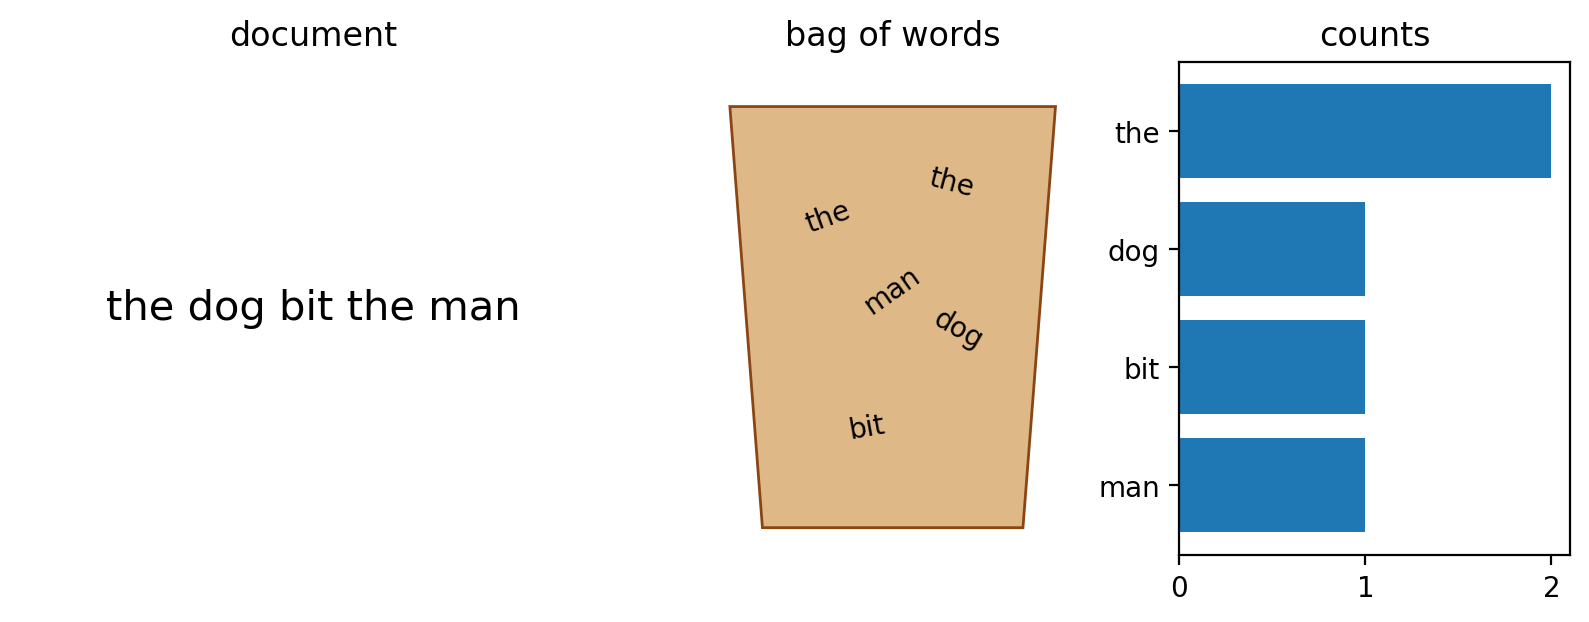

In [7]:
sentence = 'the dog bit the man'
words = sentence.split()
spots = [(2.0, 3.6, 20), (4.0, 2.3, -30), (2.6, 1.3, 10),
         (3.9, 4.0, -15), (3.0, 2.7, 35)]

fig, axes = plt.subplots(1, 3, figsize=(10, 3.2),
                         width_ratios=[3, 2, 2])
axes[0].text(0.5, 0.5, sentence, ha='center', va='center', fontsize=15)
axes[0].set_title('document')
bag = plt.Polygon([(1, 0.3), (5, 0.3), (5.5, 5), (0.5, 5)],
                  fc='burlywood', ec='saddlebrown')
axes[1].add_patch(bag)
for word, (x, y, angle) in zip(words, spots):
    axes[1].text(x, y, word, ha='center', rotation=angle)
axes[1].set(xlim=(0, 6), ylim=(0, 5.5), title='bag of words')
for ax in axes[:2]:
    ax.axis('off')
counts = pd.Series(words).value_counts()
axes[2].barh(counts.index[::-1], counts.values[::-1])
axes[2].set(title='counts', xticks=[0, 1, 2])
plt.show()

- The bag holds the five words with no order; the counts are the row of
  the table: `the` 2, `dog` 1, `bit` 1, `man` 1.

### The document-term matrix

Stack the rows: one row per document, one column per term, one count per
cell. The columns together are the **vocabulary**. `CountVectorizer` builds
the matrix
([docs](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html)).

In [8]:
vectorizer = CountVectorizer()
toy_counts = vectorizer.fit_transform(toy)
toy_counts

<3x4 sparse matrix of type '<class 'numpy.int64'>'
	with 9 stored elements in Compressed Sparse Row format>

- `.fit` learns the vocabulary from the documents; `.transform` counts
  each document's words against it. `fit_transform` does both.
- The result is a **sparse matrix**: 3 rows, 4 columns, 9 stored cells.
  It stores the nonzero cells only, which matters once the matrix has
  thousands of columns.

In [9]:
vectorizer.get_feature_names_out()

array(['big', 'class', 'data', 'science'], dtype=object)

In [10]:
bow = pd.DataFrame(toy_counts.toarray(),
                   columns=vectorizer.get_feature_names_out(),
                   index=['doc 1', 'doc 2', 'doc 3'])
bow

,big,class,data,science
doc 1,4,1,1,0
doc 2,1,0,2,1
doc 3,1,0,1,1


- `.toarray()` writes the sparse matrix out in full, which is fine for
  three rows. `get_feature_names_out()` returns the vocabulary in column
  order, sorted alphabetically.
- The default rule lowercases the text, splits at anything that is not a
  letter or digit, and keeps words of two or more characters.

### Each row is a vector

Doc 1 is the vector (4, 1, 1, 0). With two of the four words we can draw
the three documents as arrows.

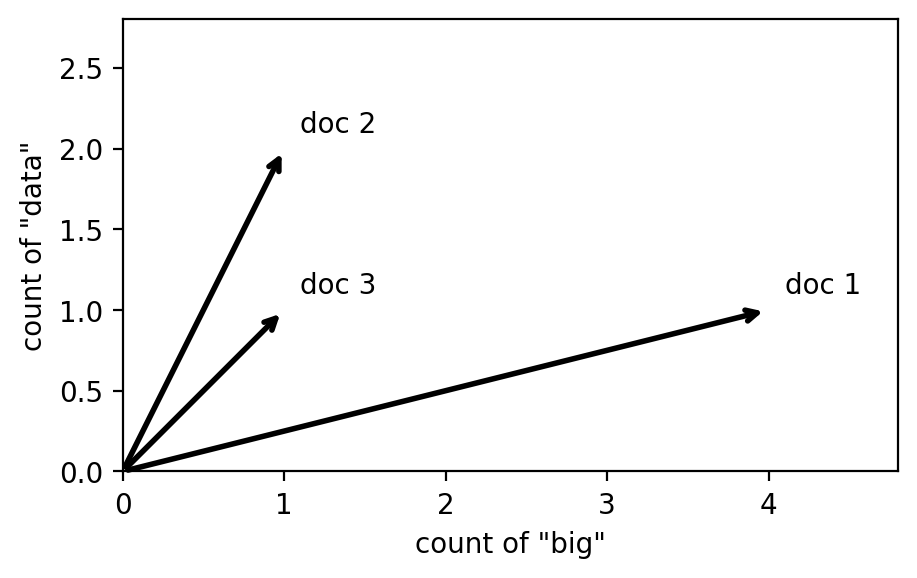

In [11]:
vecs = bow[['big', 'data']]

fig, ax = plt.subplots(figsize=(5, 3.6))
for name, (x, y) in vecs.iterrows():
    ax.annotate('', xy=(x, y), xytext=(0, 0),
                arrowprops={'arrowstyle': '->', 'lw': 2})
    ax.text(x + 0.1, y + 0.1, name)
ax.set(xlim=(0, 4.8), ylim=(0, 2.8), xlabel='count of "big"',
       ylabel='count of "data"')
ax.set_aspect('equal')
plt.show()

- Doc 2 and doc 3 point in nearly the same direction; doc 1 points along
  the `big` axis. The **direction** of an arrow says what the document is
  about. Its **length** says how long the document is.
- With four words the arrows live in four dimensions, and with the essays
  in thousands. The geometry stays the same: alike documents point the
  same way.

### The dot product

For two vectors $\vec u$ and $\vec v$ have the same length, the **dot
product** is the sum of the products of matching entries:

$$\vec u \cdot \vec v = \sum_{i=1}^{n} u_i v_i
= u_1 v_1 + u_2 v_2 + \dots + u_n v_n$$

Doc 1 and doc 2: $4 \times 1 + 1 \times 0 + 1 \times 2 + 0 \times 1 = 6$.
The dot product is large when both documents have large counts on the
same words.

The dot product also has a **geometric** definition:

$$\vec u \cdot \vec v = \|\vec u\| \, \|\vec v\| \cos\theta$$

where $\theta$ is the angle between the two vectors and
$\|\vec u\| = \sqrt{u_1^2 + u_2^2 + \dots + u_n^2}$ is the length of
$\vec u$. 

### Angles and similarity

**Key idea.** If two vectors are pointing toward similar directions, the **smaller** the angle
$\theta$ between them.

The next cell draws three pairs of vectors. Each title gives the angle
between the pair and its cosine, computed from the entries with the two
definitions of the dot product.

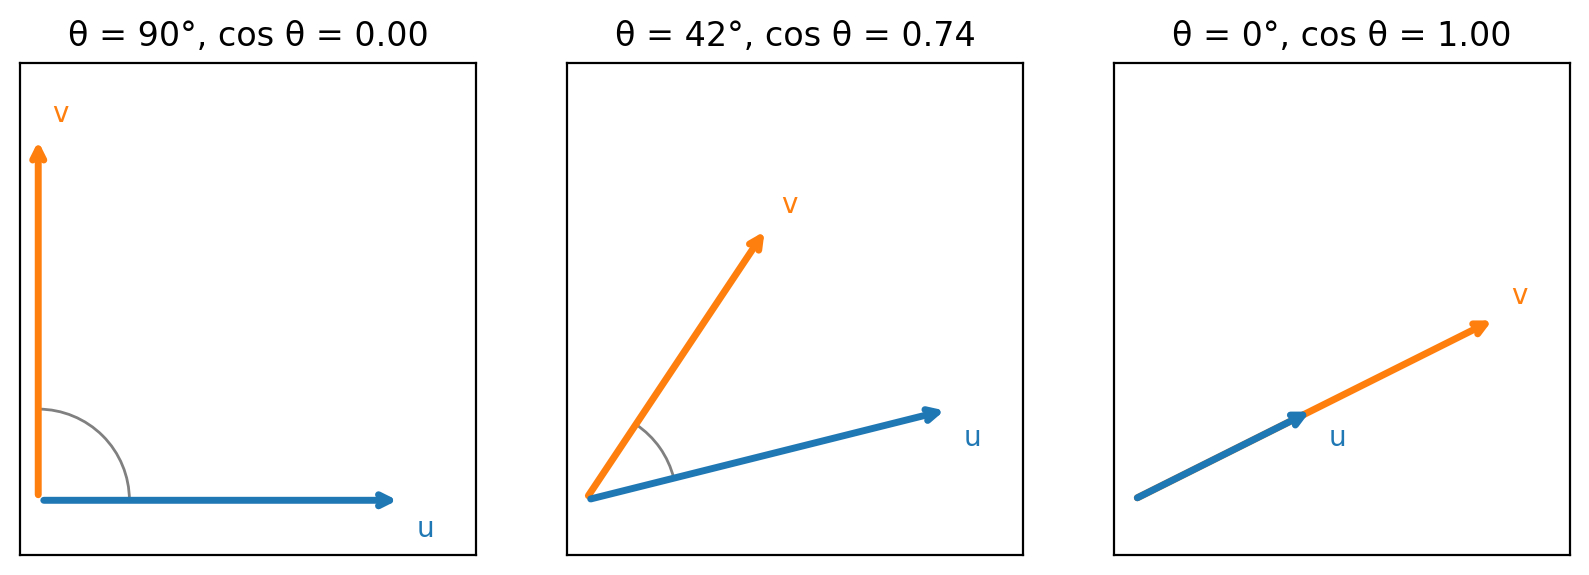

In [12]:
pairs = [((4, 0), (0, 4)), ((4, 1), (2, 3)), ((2, 1), (4, 2))]

fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
for ax, (u, v) in zip(axes, pairs):
    for vec, name, color, dy in [(v, 'v', 'C1', 0.15),
                                 (u, 'u', 'C0', -0.4)]:
        ax.annotate('', xy=vec, xytext=(0, 0),
                    arrowprops={'arrowstyle': '->', 'lw': 2.5,
                                'color': color})
        ax.text(vec[0] + 0.15, vec[1] + dy, name, color=color)
    cos = np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))
    theta = np.degrees(np.arccos(cos))
    start = np.degrees(np.arctan2(u[1], u[0]))
    ax.add_patch(Arc((0, 0), 2, 2, theta1=start,
                     theta2=start + theta, color='gray'))
    ax.set(xlim=(-0.2, 4.8), ylim=(-0.6, 4.8), xticks=[], yticks=[],
           title=f'θ = {theta:.0f}°, cos θ = {cos:.2f}')
    ax.set_aspect('equal')
plt.show()

- The smaller the angle $\theta$, the **larger** $\cos\theta$.
- The largest value of $\cos\theta$ is 1, reached when $\theta = 0$. In the
  third panel $\vec v = 2\vec u$: twice as long, the same direction.
- So the more alike two vectors are, the larger $\cos\theta$.

### Cosine similarity

Divide the dot product by both lengths, and only the angle is left:

$$\text{cosine similarity}(\vec u, \vec v) = \cos\theta
= \frac{\vec u \cdot \vec v}{\|\vec u\| \, \|\vec v\|}$$

- Counts are never negative, so cosine similarity runs from 0 to 1.
- 1 means the same direction (the same word proportions); 0 means the
  documents share no word.
- To find the most alike pair in a corpus: represent each document as a
  vector, compute the cosine similarity of every pair, and return the pair
  with the largest value. `cosine_similarity` does the second step for every
  pair of rows
  ([docs](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise.cosine_similarity.html)).

### ❓ Question

Use the count table of the three toy documents.

1. Which two documents have the highest **dot product**?
2. Which two documents have the highest **cosine similarity**?

<details><summary>Answer</summary>

**Dot product: doc 1 and doc 2** (6, against 5 for doc 1 and doc 3, and 4
for doc 2 and doc 3). **Cosine: doc 2 and doc 3** (0.943). Doc 1 wins the
dot product because it is the longest document, with four `big`. Once the
lengths are divided out, doc 2 and doc 3 are the pair with the closest word
proportions.

</details>

In [13]:
bow @ bow.T   # the dot product of every pair of rows

,doc 1,doc 2,doc 3
doc 1,18,6,5
doc 2,6,6,4
doc 3,5,4,3


In [14]:
pd.DataFrame(cosine_similarity(bow), index=bow.index,
             columns=bow.index).round(3)

,doc 1,doc 2,doc 3
doc 1,1.000,0.577,0.680
doc 2,0.577,1.000,0.943
doc 3,0.680,0.943,1.000


- `@` is matrix multiplication; `bow @ bow.T` holds every row's dot
  product with every row. The diagonal is each row with itself.
- `cosine_similarity(bow)` divides each of those by the two lengths.

### Cosine similarity ignores length

A document that says the same things at twice the length points the same
way.

In [15]:
twice = bow.loc[['doc 2']] * 2
cosine_similarity(bow.loc[['doc 2']], twice)

array([[1.]])

- The essays run from 934 to 5,559 words. Without this property, the long
  essays would look alike because they are long.

### Three limits of raw counts

1. **Order is gone.** `the dog bit the man` equals `the man bit the dog`.
2. **Meaning is gone.** `bank` by a river and `bank` with money share a
   column.
3. **Every word counts the same.** `the` has the largest count in every
   English document, and it says nothing about any of them.

The first two limits need other representations (word embeddings, which
BERTopic uses in Part 3). The third has a fix inside the count matrix:
weight the words.

## TF-IDF: what makes a word important?

**Issue.** The bag of words model does not know which terms are important
in a document.

> my brother has a friend named **billy** who has an uncle named **billy**

`has` and `billy` both appear twice in this document. `has` is a common
word in every document; `billy` is not.

**Observation.** If a term is important in a document, it appears often
**in that document** but not often **in other documents**. The next three
slides build a score for each term that keeps this in mind. The terms with
the highest scores then summarize the document.

### Term frequency

The **term frequency** of a term $t$ in a document $d$ is the share of
the words in $d$ that equal $t$:

$$\mathrm{tf}(t, d) = \frac{\text{number of occurrences of } t \text{ in } d}
{\text{total number of terms in } d}$$

**Example.** What is the term frequency of `billy` in the document above?

**Answer.** $2 / 13$: the document has 13 words, and two of them are
`billy`.

**Intuition.** Terms that occur often within a document matter to the
document's meaning.

$$\mathrm{tf}(t, d) \text{ large} \implies t \text{ occurs often in } d
\qquad
\mathrm{tf}(t, d) \text{ small} \implies t \text{ occurs rarely in } d$$

**Issue.** `has` also has a term frequency of $2 / 13$, and it matters less
than `billy`.

### Inverse document frequency

The **inverse document frequency** of a term $t$ in a collection of
documents is:

$$\mathrm{idf}(t) = \log \left( \frac{\text{total number of documents}}
{\text{number of documents in which } t \text{ appears}} \right)$$

**Example.** What is the inverse document frequency of `billy` in these
three documents?

- my brother has a friend named **billy** who has an uncle named **billy**
- my favorite artist is named jilly boel
- why does he talk about someone named **billy** so often

**Answer.** $\log(3 / 2) \approx 0.4055$.

**Note.** This is the natural logarithm, `np.log`. The base does not
matter, as long as every calculation uses the same one.

**Intuition.** If a word appears in every document (`the`, `has`), it is
not a good summary of any one document. Think of $\mathrm{idf}(t)$ as the
rarity factor of $t$ across documents.

$$\mathrm{idf}(t) \text{ large} \implies t \text{ rare across documents}
\qquad
\mathrm{idf}(t) \text{ small} \implies t \text{ common across documents}$$

### Intuition: put the two together

**Goal.** Measure how important term $t$ is to document $d$. The same
goal, in other words: find the terms that best summarize $d$.

- If $\mathrm{tf}(t, d)$ is small, $t$ does not occur often in $d$, so $t$
  cannot matter much to $d$.
- If $\mathrm{idf}(t)$ is small, $t$ occurs in most documents, so $t$
  cannot matter much to $d$ in particular.
- If $\mathrm{tf}(t, d)$ and $\mathrm{idf}(t)$ are both large, then $t$
  **occurs often in $d$ but rarely overall**. That makes $t$ important to
  $d$: a good summary of $d$.

### Term frequency-inverse document frequency

The **TF-IDF** of term $t$ in document $d$ is the product:

$$\text{tf-idf}(t, d) = \mathrm{tf}(t, d) \cdot \mathrm{idf}(t)
= \frac{\text{number of occurrences of } t \text{ in } d}
{\text{total number of terms in } d}
\cdot \log \left( \frac{\text{total number of documents}}
{\text{number of documents in which } t \text{ appears}} \right)$$

- If $\text{tf-idf}(t, d)$ is large, $t$ is important to $d$: it occurs
  often in $d$ but rarely across the documents.

**Note.** TF-IDF is a heuristic. There is no proof that it performs well;
it works well in practice.

**Note.** One TF-IDF value on its own says little. To know whether
$\text{tf-idf}(t, d)$ is large, compare it with the TF-IDF of the other
terms in the same document.

### ❓ Question

What is the TF-IDF of `science` in doc 2, `data big data science`?

| | big | class | data | science |
|---|---|---|---|---|
| doc 1: `big big big big data class` | 4 | 1 | 1 | 0 |
| doc 2: `data big data science` | 1 | 0 | 2 | 1 |
| doc 3: `science big data` | 1 | 0 | 1 | 1 |

<details><summary>Answer</summary>

$$\text{tf-idf}(\text{science}, \text{doc 2})
= \frac{1}{4} \cdot \log\left(\frac{3}{2}\right) \approx 0.101$$

One of doc 2's four words is `science`, and two of the three documents
contain it. On its own, 0.101 is neither big nor small. The next cells
compute the TF-IDF of every term in every document, so that the values
can be compared.

</details>

### Compute tf, idf, and tf-idf on the toy matrix

The count matrix already holds the numerators of the term frequencies.
Divide each row by its total, then multiply each column by its idf.

In [16]:
tf = bow.div(bow.sum(axis=1), axis=0)
tf.round(3)

,big,class,data,science
doc 1,0.667,0.167,0.167,0.000
doc 2,0.250,0.000,0.500,0.250
doc 3,0.333,0.000,0.333,0.333


In [17]:
idf = np.log(len(bow) / (bow > 0).sum())
idf.round(3)

big        0.000
class      1.099
data       0.000
science    0.405
dtype: float64

In [18]:
tfidf_toy = tf * idf
tfidf_toy.round(3)

,big,class,data,science
doc 1,0.0,0.183,0.0,0.000
doc 2,0.0,0.000,0.0,0.101
doc 3,0.0,0.000,0.0,0.135


- `bow.sum(axis=1)` is the total number of terms in each document.
  `(bow > 0).sum()` counts, for each column, the documents that contain the
  word, and `len(bow)` is the total number of documents.

### Interpreting the TF-IDF values

- The TF-IDF of `class` in doc 1 is about 0.18.
- The TF-IDF of `data` in doc 2 is 0.

**Note.** There are two ways for $\text{tf-idf}(t, d)$ to be 0:

- $t$ appears in every document, so
  $\mathrm{idf}(t) = \log(\text{number of documents} / \text{number of documents}) = \log 1 = 0$.
- $t$ does not appear in $d$, so $\mathrm{tf}(t, d) = 0 / \text{len}(d) = 0$.

The term that best summarizes a document is the one with the highest
TF-IDF in that document's row.

In [19]:
tfidf_toy.idxmax(axis=1)

doc 1      class
doc 2    science
doc 3    science
dtype: object

- `class` summarizes doc 1, and `science` summarizes doc 2 and doc 3. `big`
  and `data` are in every document, so they summarize none of them.

### The role of the log in idf

The formula takes the log of the ratio, not the ratio itself. For any
positive $x$, $\log(x)$ is smaller than $x$, and it grows slowly. The log
**dampens** the ratio, and that does two jobs.

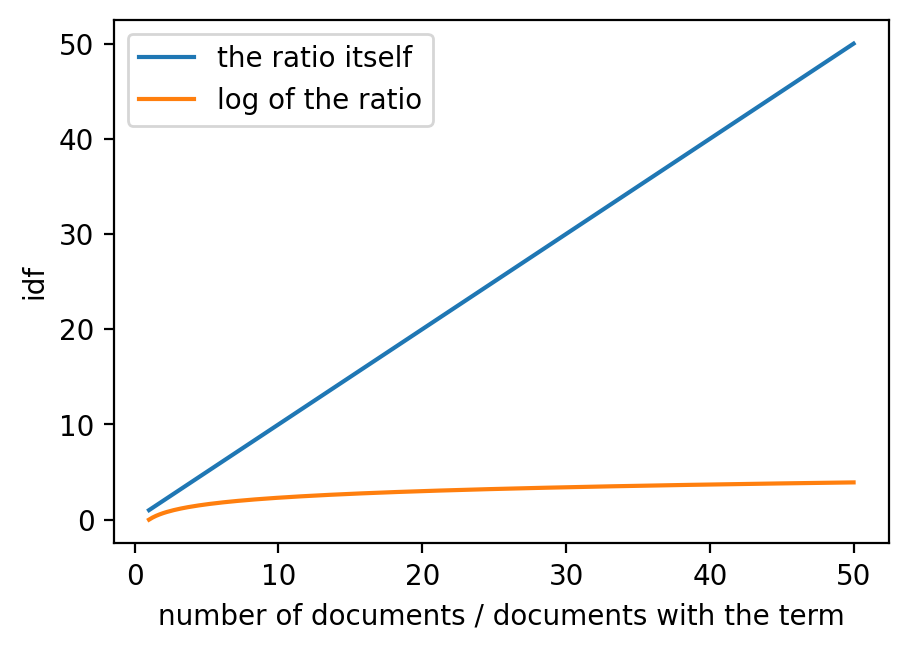

In [20]:
x = np.linspace(1, 50, 200)
fig, ax = plt.subplots(figsize=(5, 3.4))
ax.plot(x, x, label='the ratio itself')
ax.plot(x, np.log(x), label='log of the ratio')
ax.set(xlabel='number of documents / documents with the term',
       ylabel='idf')
ax.legend()
plt.show()

### Job 1 of the log: a word in nearly every document gets weight near 0

If a word is very common, the ratio is close to 1, and the log of the
ratio is close to 0.

In [21]:
print(f'ratio {1000 / 999:.3f}')
print(f'log   {np.log(1000 / 999):.3f}')

ratio 1.001
log   0.001


- Take `the`, in 999 of 1,000 documents. Without the log, its idf would be
  1.001, so its TF-IDF would be almost its full term frequency, and `the`
  would top the list for every document. With the log, its idf is 0.001,
  and `the` drops out of every list.

### Job 2 of the log: two rare words get similar weights

A word seen in 2 of 50 documents and a word seen in 2 of 500 are both rare,
so their idf should be similar.

In [22]:
for documents in [50, 500]:
    ratio = documents / 2
    print(f'{documents:4d} documents: ratio {ratio:6.1f}'
          f'   log {np.log(ratio):.2f}')

  50 documents: ratio   25.0   log 3.22
 500 documents: ratio  250.0   log 5.52


- Without the log, the second word would weigh ten times the first, and the
  weight of every rare word would grow with the size of the corpus. With the
  log, 25 becomes 3.2 and 250 becomes 5.5: still different, but close.
- So the log keeps the common words near 0 and keeps the rare words from
  running away. A summary score needs both.

### `TfidfVectorizer` does the same job, with two changes

In practice, use an existing implementation. `TfidfVectorizer` builds the
count matrix and weights it in one step
([docs](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html)).

In [23]:
tfidf_sklearn = TfidfVectorizer().fit_transform(toy)
pd.DataFrame(tfidf_sklearn.toarray(),
             columns=vectorizer.get_feature_names_out(),
             index=bow.index).round(3)

,big,class,data,science
doc 1,0.897,0.38,0.224,0.000
doc 2,0.388,0.00,0.775,0.499
doc 3,0.523,0.00,0.523,0.673


- The numbers differ from the hand version for two reasons. scikit-learn
  uses $\mathrm{idf}(t) = \log\frac{1 + \text{number of documents}}{1 + \text{documents with } t} + 1$,
  so a word in every document keeps a small weight instead of 0. It then
  scales every row to length 1, so the cosine similarity of two rows is
  their dot product.
- The ranking inside a row can change. By hand, `big` and `data` score 0
  everywhere, so `class` leads doc 1 and `science` leads doc 2. Here the
  floor of 1 keeps them in: `big` leads doc 1 (0.897) and `data` leads doc 2
  (0.775). Only doc 3 agrees. The formula is a choice; read the docs of the
  implementation you use. Part 2 removes the words in every essay with a
  stop list before weighting.

## Part 2: the 85 essays as a matrix

The same four steps, on real text: count, weight, compare, and then decide
who wrote the disputed essays.

### Count every word of every essay

In [24]:
count_vec = CountVectorizer()
counts = count_vec.fit_transform(essays['text'])
counts

<85x8547 sparse matrix of type '<class 'numpy.int64'>'
	with 59027 stored elements in Compressed Sparse Row format>

### ❓ Question

What is the shape of `counts`, and what does each number mean?

<details><summary>Answer</summary>

**85 rows and 8,547 columns.** One row per essay, one column per distinct
word in the whole corpus. Only 59,027 of the 726,495 cells are nonzero,
about 8 percent, which is why the sparse format matters.

</details>

In [25]:
counts.shape

(85, 8547)

### The most frequent words

Sum each column to get a corpus count per word.

In [26]:
vocab = count_vec.get_feature_names_out()
totals = pd.Series(np.asarray(counts.sum(axis=0)).ravel(),
                   index=vocab)
totals.sort_values(ascending=False).head(10)

the      17393
of       11507
to        6911
and       5033
in        4395
be        3793
that      2751
it        2521
is        2161
which     2042
dtype: int64

- `counts.sum(axis=0)` is a 1-row matrix; `np.asarray(...).ravel()` turns
  it into a flat array of 8,547 numbers, one per word.
- `the`, `of`, `to`, `and`, `in`: the most frequent words of every English
  corpus. None says what an essay is about.

### Words per essay

Sum each row to get the length of each essay in words.

In [27]:
essays['n_words'] = np.asarray(counts.sum(axis=1)).ravel()
essays['n_words'].describe().round(0)

count      85.0
mean     2154.0
std       719.0
min       934.0
25%      1660.0
50%      1996.0
75%      2553.0
max      5559.0
Name: n_words, dtype: float64

- From 934 to 5,559 words, median 1,996. The lengths differ by a factor of
  six, so raw counts compare lengths as much as wording.

### Stop words: drop the words that carry no subject

`stop_words='english'` removes a built-in list of 318 common words before
counting.

In [28]:
count_vec = CountVectorizer(stop_words='english')
counts = count_vec.fit_transform(essays['text'])
vocab = count_vec.get_feature_names_out()
totals = pd.Series(np.asarray(counts.sum(axis=0)).ravel(),
                   index=vocab)
totals.sort_values(ascending=False).head(10)

states          842
government      824
state           695
power           600
people          524
constitution    454
union           361
national        340
federal         319
great           289
dtype: int64

- Now the top words are `states`, `government`, `state`, `power`,
  `people`, `constitution`: the subject of the corpus.

In [29]:
style_words = ['upon', 'whilst', 'while', 'on']
[word in ENGLISH_STOP_WORDS for word in style_words]

[True, False, True, True]

- The list removes `upon`, `while`, and `on`, and keeps `whilst`. Keep
  that in mind: the end of Part 2 comes back to these four words.

### TF-IDF for the essays

Weight the counts, with two settings.

In [30]:
tfidf_vec = TfidfVectorizer(stop_words='english', min_df=2)
tfidf = tfidf_vec.fit_transform(essays['text'])
terms = tfidf_vec.get_feature_names_out()
tfidf.shape

(85, 5164)

- `min_df=2` drops every word that appears in one essay only: 8,276
  columns become 5,164. A word in one essay cannot link it to any other.
- `terms` is the vocabulary of this matrix. The column order is the same
  for every matrix built from it.

### Essay 10 by count and by TF-IDF

Build a count matrix with the same settings, so the columns match, and
compare the two weightings for essay 10 (Madison's essay on faction).

In [31]:
count_vec = CountVectorizer(stop_words='english', min_df=2)
counts = count_vec.fit_transform(essays['text'])

essay10 = pd.DataFrame({'count': counts[9].toarray().ravel(),
                        'tfidf': tfidf[9].toarray().ravel()},
                       index=terms)
essay10.sort_values('count', ascending=False).head(8)

,count,tfidf
faction,16,0.281671
number,15,0.142549
interests,14,0.150677
public,14,0.113964
greater,13,0.136402
government,13,0.093084
majority,12,0.185467
different,12,0.102392


In [32]:
essay10.sort_values('tfidf', ascending=False).head(8)

,count,tfidf
faction,16,0.281671
majority,12,0.185467
parties,12,0.168225
interests,14,0.150677
republic,8,0.143774
rights,12,0.143506
number,15,0.142549
greater,13,0.136402


- Row 9 is essay 10, because positions start at 0.
- By count, `number`, `public`, and `government` rank high; every essay
  uses them. By tf-idf, `faction`, `majority`, `parties`, and `republic`
  rise: the words of this essay's argument.

### Cosine similarity between every pair of essays

In [33]:
sim = pd.DataFrame(cosine_similarity(tfidf),
                   index=essays['essay'], columns=essays['essay'])
sim.round(2).iloc[:5, :5]

essay,1,2,3,4,5
essay,,,,,
1,1.00,0.23,0.18,0.16,0.15
2,0.23,1.00,0.23,0.22,0.21
3,0.18,0.23,1.00,0.32,0.23
4,0.16,0.22,0.32,1.00,0.28
5,0.15,0.21,0.23,0.28,1.00


- 85 by 85. The diagonal is 1 (each essay with itself), and the matrix is
  symmetric. Row and column labels are essay numbers.

### The essays nearest to essay 10

In [34]:
sim[10].drop(10).sort_values(ascending=False).head(5)

essay
51    0.347164
22    0.280068
58    0.257540
62    0.256897
14    0.253953
Name: 10, dtype: float64

- Essay 51 is nearest (0.35). Both essays argue that a large republic with
  many interests keeps any one faction from ruling. Then 22 (Hamilton), 58
  and 62 (disputed), and 14 (Madison).

### Route 1: mean similarity to each author's essays

For every essay, average its similarity to the 51 Hamilton essays and to
the 14 Madison essays. Leave each essay's similarity to itself out.

In [35]:
known = sim.copy()
np.fill_diagonal(known.values, np.nan)
essays['to_hamilton'] = known[authors['Hamilton']].mean(axis=1).values
essays['to_madison'] = known[authors['Madison']].mean(axis=1).values
essays[essays['author'] == 'Disputed'][
    ['essay', 'to_hamilton', 'to_madison']].round(3)

,essay,to_hamilton,to_madison
48,49,0.164,0.222
49,50,0.110,0.146
50,51,0.181,0.255
51,52,0.150,0.191
52,53,0.169,0.205
53,54,0.145,0.180
54,55,0.164,0.203
55,56,0.159,0.188
56,57,0.167,0.198
57,58,0.170,0.213


- `known[authors['Hamilton']]` selects the 51 Hamilton columns;
  `.mean(axis=1)` averages across them, so each essay gets one number:
  how much it reads like Hamilton's essays as a group.
- All 12 disputed essays are closer to Madison's essays.

### Plot every essay by its two similarities

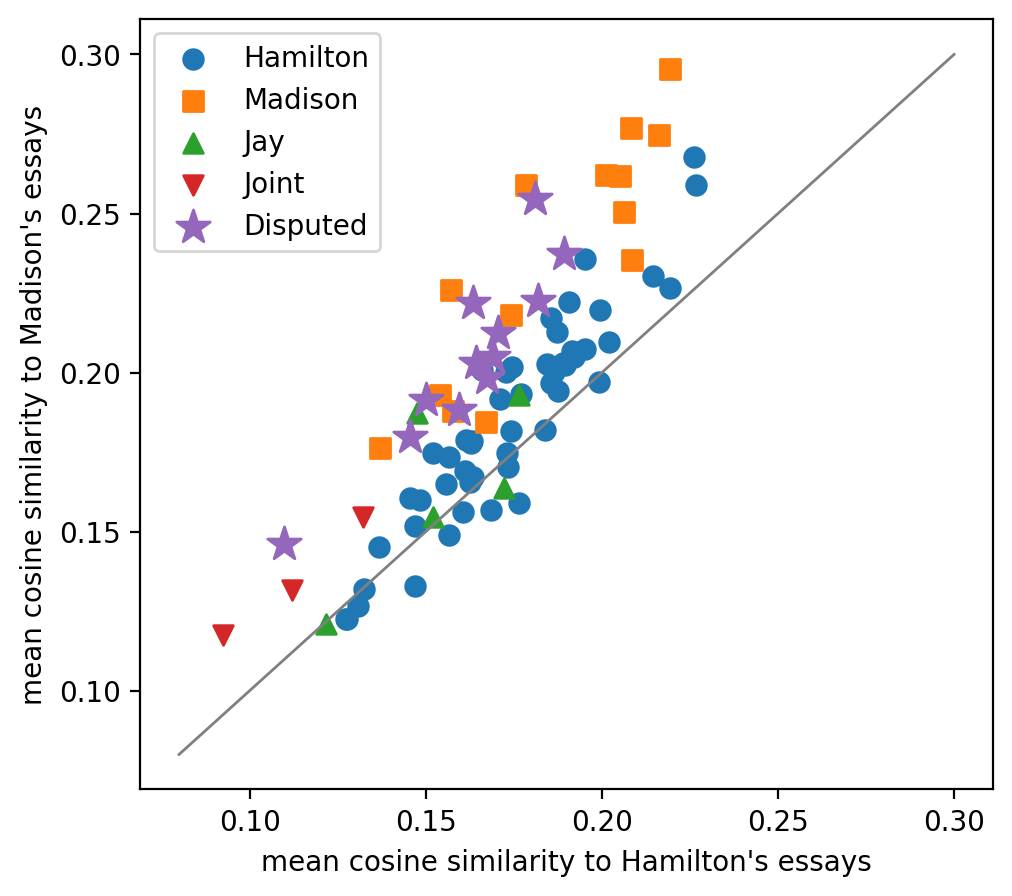

In [36]:
styles = {'Hamilton': 'o', 'Madison': 's', 'Jay': '^',
          'Joint': 'v', 'Disputed': '*'}

fig, ax = plt.subplots(figsize=(5.5, 5))
for author, marker in styles.items():
    part = essays[essays['author'] == author]
    ax.scatter(part['to_hamilton'], part['to_madison'], marker=marker,
               s=160 if author == 'Disputed' else 50, label=author)
ax.plot([0.08, 0.30], [0.08, 0.30], color='grey', lw=1)
ax.set(xlabel="mean cosine similarity to Hamilton's essays",
       ylabel="mean cosine similarity to Madison's essays")
ax.legend()
plt.show()

- Above the grey line means closer to Madison. Every star is above it.
- So are some of Hamilton's own essays. The next cell counts them.

In [37]:
closer_to_madison = essays['to_madison'] > essays['to_hamilton']
pd.crosstab(essays['author'], closer_to_madison)

col_0,False,True
author,,
Disputed,0,12
Hamilton,12,39
Jay,2,3
Joint,0,3
Madison,0,14


- 12 of Hamilton's 51 essays read closer to Madison's by this rule. A rule
  that misfiles nearly a quarter of the known essays is weak evidence.
- The reason: tf-idf measures **subject**. The disputed essays are about
  the separation of powers and the House, and Madison wrote more on those
  subjects than Hamilton. A plausible answer can come from the wrong
  signal.

### Route 2: style, the words the stop list threw away

Mosteller and Wallace did not count subject words. They counted words that
a writer uses whatever the subject: `upon` against `on`, `whilst` against
`while`. Count only those four, with `vocabulary=`, and turn the counts
into rates per 1,000 words.

In [38]:
style_vec = CountVectorizer(vocabulary=style_words)
style = pd.DataFrame(style_vec.fit_transform(essays['text']).toarray(),
                     columns=style_vec.get_feature_names_out())
style = style.div(essays['n_words'], axis=0) * 1000
style['author'] = essays['author']
style.groupby('author').mean().round(2)

,upon,whilst,while,on
author,,,,
Disputed,0.16,0.38,0.00,8.32
Hamilton,3.38,0.01,0.28,3.42
Jay,0.12,0.00,0.21,5.17
Joint,0.39,0.33,0.00,6.84
Madison,0.17,0.32,0.00,7.81


- `vocabulary=` fixes the columns in advance; the stop list does not
  apply. Dividing by `n_words` removes essay length.
- Hamilton writes `upon` 3.4 times per 1,000 words; Madison 0.2; the
  disputed essays 0.2. For `whilst` the order flips: Hamilton 0.01,
  Madison 0.3, disputed 0.4.

### Plot `upon` for every essay

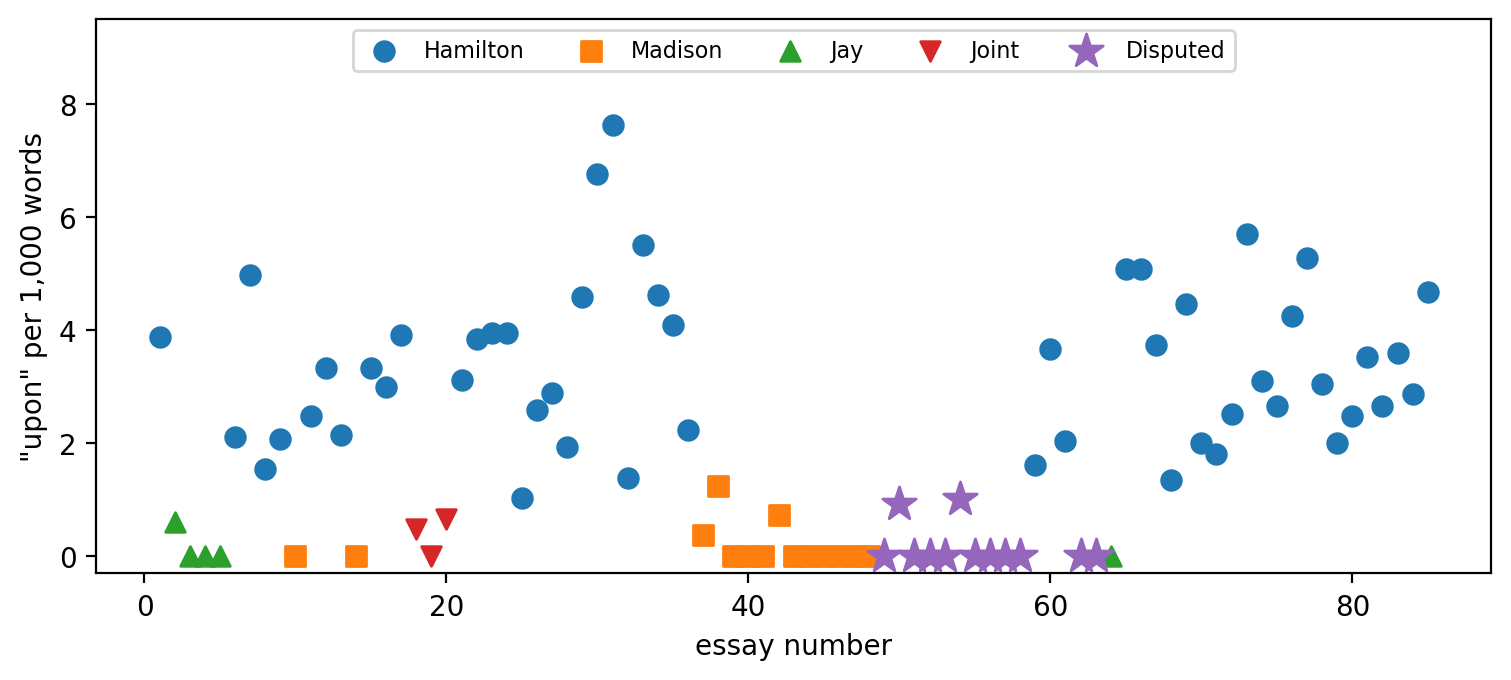

In [39]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for author, marker in styles.items():
    part = style[style['author'] == author]
    ax.scatter(essays.loc[part.index, 'essay'], part['upon'],
               marker=marker, s=160 if author == 'Disputed' else 50,
               label=author)
ax.set(xlabel='essay number', ylabel='"upon" per 1,000 words',
       ylim=(-0.3, 9.5))
ax.legend(ncol=5, fontsize=8, loc='upper center')
plt.show()

In [40]:
style.groupby('author')['upon'].agg(['min', 'max']).round(2)

,min,max
author,,
Disputed,0.00,1.02
Hamilton,1.03,7.63
Jay,0.00,0.61
Joint,0.00,0.67
Madison,0.00,1.24


- Hamilton's lowest rate is 1.03 per 1,000 words; Madison's highest is
  1.24, and the disputed essays top out at 1.02. One word nearly separates
  the known authors, and it puts the 12 disputed essays with Madison.
- Mosteller and Wallace used about 30 such words in a Bayesian model, and
  reached the same answer for all 12.

### What the two routes say

- Both routes point to Madison, and historians now agree.
- The subject route misfiles 12 of Hamilton's essays. The style route
  separates the known authors nearly without error. Style is the better
  evidence for *who wrote it*; subject words are the evidence for *what it
  is about*.
- The stop-word list removed `upon`, `while`, and `on` before the first
  matrix was built. The default setting threw away the best evidence. A
  representation is a measurement choice, and the choice should follow
  the question.

Mosteller, F., and D. L. Wallace (1963). "Inference in an Authorship
Problem." *Journal of the American Statistical Association* 58(302):
275–309. [doi:10.1080/01621459.1963.10500849](https://doi.org/10.1080/01621459.1963.10500849).

## Part 3: topic models

The tf-idf matrix has 5,164 columns. Nobody reads 5,164 columns. A reader
wants a few themes: which essays are about the courts, which about the
executive, and how much of each essay is each theme.

A **topic model** finds groups of words that tend to appear in the same
documents, and gives every document a weight on each group. The analyst
chooses how many groups to look for, and names them afterwards.

### NMF: a matrix written as the product of two smaller ones

Non-negative matrix factorization (`NMF`,
[docs](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.NMF.html))
looks for

$$X \approx W H$$

| Matrix | Rows × columns | Holds |
|---|---|---|
| $X$ | documents × words | the tf-idf matrix |
| $W$ | documents × topics | how much of each topic each document has |
| $H$ | topics × words | how much each word belongs to each topic |

No entry may be negative, so each document row is a sum of topic word
lists with positive weights: the parts add up (Lee and Seung 1999,
[*Nature*](https://www.nature.com/articles/44565)). The analyst chooses the
number of topics, `n_components`.

### A toy: six documents, eight words

Three documents about courts, three about elections, with `people` in
both. The counts are made up to keep the picture clear.

In [41]:
toy_words = ['court', 'judge', 'law', 'trial',
             'vote', 'house', 'election', 'people']
X = pd.DataFrame(
    [[3, 2, 2, 1, 0, 0, 0, 1],
     [2, 3, 1, 2, 0, 0, 0, 0],
     [1, 1, 3, 2, 0, 0, 0, 1],
     [0, 0, 0, 0, 3, 2, 2, 1],
     [0, 0, 1, 0, 2, 3, 1, 1],
     [0, 0, 0, 0, 1, 2, 3, 2]],
    columns=toy_words, index=[f'doc {i}' for i in range(1, 7)])
X

,court,judge,law,trial,vote,house,election,people
doc 1,3,2,2,1,0,0,0,1
doc 2,2,3,1,2,0,0,0,0
doc 3,1,1,3,2,0,0,0,1
doc 4,0,0,0,0,3,2,2,1
doc 5,0,0,1,0,2,3,1,1
doc 6,0,0,0,0,1,2,3,2


### Fit NMF with two topics

`fit_transform` returns $W$; the fitted model keeps $H$ as `components_`.

In [42]:
toy_nmf = NMF(n_components=2, random_state=0)
W = pd.DataFrame(toy_nmf.fit_transform(X), index=X.index,
                 columns=['topic 0', 'topic 1'])
H = pd.DataFrame(toy_nmf.components_, index=W.columns,
                 columns=X.columns)
H.round(2)

,court,judge,law,trial,vote,house,election,people
topic 0,8.15,8.07,7.84,6.51,0.00,0.00,0.00,2.44
topic 1,0.00,0.00,0.19,0.00,1.36,1.57,1.37,0.90


- Each row of $H$ is a topic: topic 0 weights `court`, `judge`, `law`,
  `trial`; topic 1 weights `vote`, `house`, `election`. `people` gets some
  weight in both.
- `random_state=0` fixes the starting point, so the run repeats.

In [43]:
W.round(2)

,topic 0,topic 1
doc 1,0.27,0.04
doc 2,0.25,0.00
doc 3,0.23,0.09
doc 4,0.00,1.54
doc 5,0.02,1.39
doc 6,0.00,1.48


- Each row of $W$ is a document: docs 1 to 3 load on topic 0, docs 4 to 6
  on topic 1.

### ❓ Question

Which topic does doc 5 belong to, and which of its words gives it a small
weight on the other topic?

<details><summary>Answer</summary>

**Topic 1**, with weight 1.39 against 0.02. Its one `law` is a topic 0
word, so doc 5 gets a small topic 0 weight. NMF explains every cell of
the row as a mix of the two word lists.

</details>

### Draw $X \approx W \times H$

The three matrices as heatmaps: darker is larger.

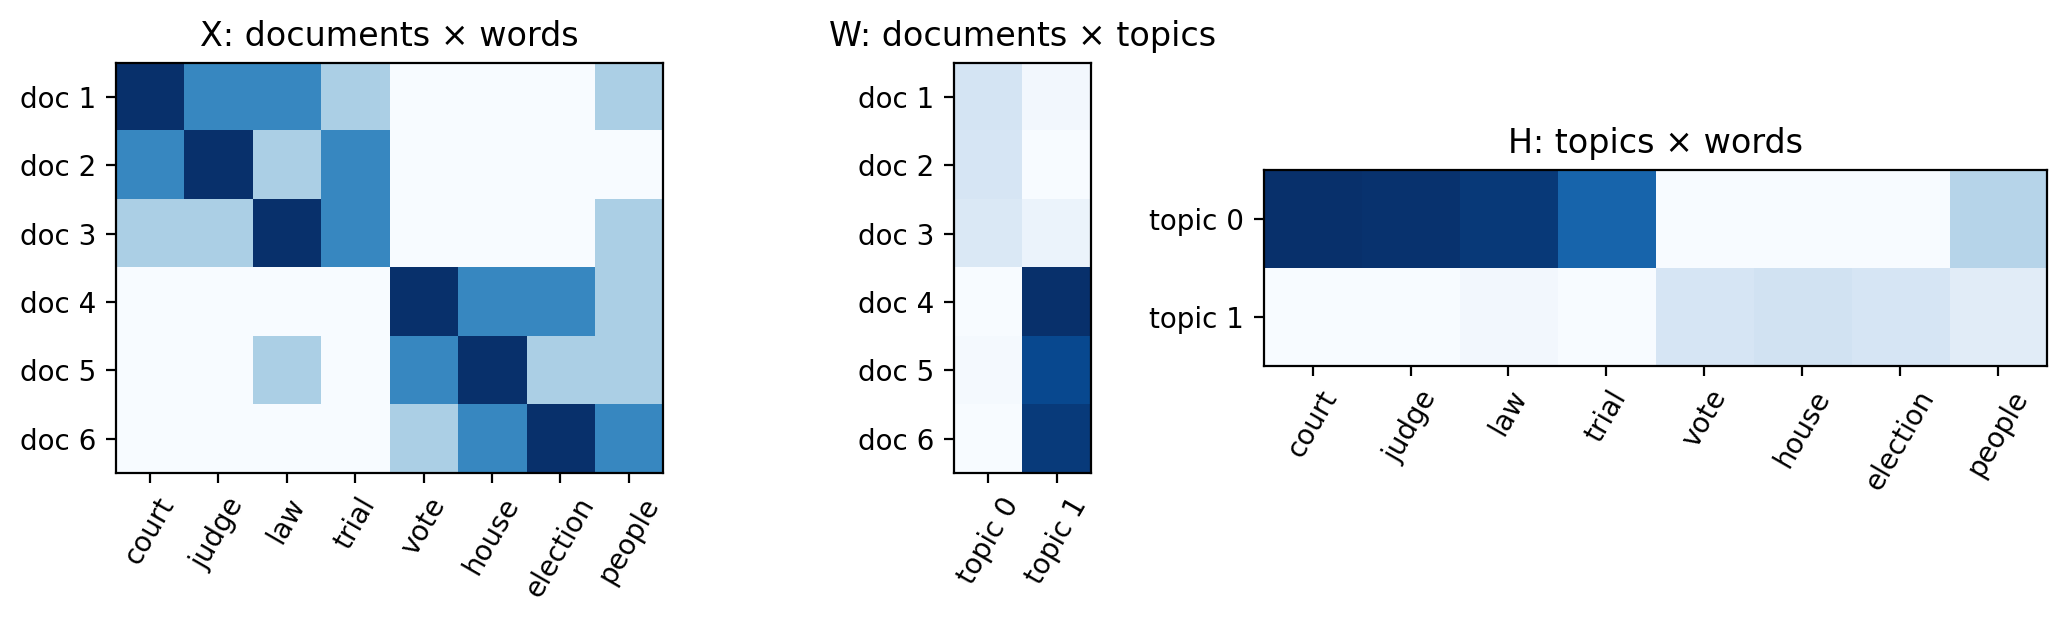

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2),
                         width_ratios=[8, 2, 8])
titles = ['X: documents × words', 'W: documents × topics',
          'H: topics × words']
for ax, m, title in zip(axes, [X, W, H], titles):
    ax.imshow(m, cmap='Blues')
    ax.set(title=title, xticks=range(m.shape[1]),
           yticks=range(m.shape[0]), xticklabels=m.columns,
           yticklabels=m.index)
    ax.tick_params(axis='x', rotation=60)
fig.tight_layout()
plt.show()

In [45]:
(W @ H).round(1)

,court,judge,law,trial,vote,house,election,people
doc 1,2.2,2.2,2.1,1.8,0.1,0.1,0.1,0.7
doc 2,2.1,2.1,2.0,1.7,0.0,0.0,0.0,0.6
doc 3,1.9,1.8,1.8,1.5,0.1,0.1,0.1,0.6
doc 4,0.0,0.0,0.3,0.0,2.1,2.4,2.1,1.4
doc 5,0.2,0.2,0.4,0.1,1.9,2.2,1.9,1.3
doc 6,0.0,0.0,0.3,0.0,2.0,2.3,2.0,1.3


- `W @ H` is close to `X`: NMF chose $W$ and $H$ to make the difference
  small. Two topic rows of eight numbers each, plus two weights per
  document, rebuild a six-by-eight matrix.
- On the essays, 4 topic rows of 5,164 numbers, plus 4 weights per essay,
  summarize 85 rows of 5,164 numbers.

### Fit four topics on the 85 essays

In [46]:
nmf = NMF(n_components=4, random_state=0, max_iter=1000)
weights = nmf.fit_transform(tfidf)
weights.shape

(85, 4)

- `weights` is $W$: 85 essays by 4 topics. `nmf.components_` is $H$: 4
  topics by 5,164 words. `max_iter=1000` gives the fit enough steps to
  settle.

### The ten strongest words of each topic

For each topic row of $H$, sort the weights and name the top ten words.

In [47]:
for k, row in enumerate(nmf.components_):
    top = row.argsort()[::-1][:10]
    print(k, ', '.join(terms[top]))

0 government, states, union, national, nations, people, war, state, power, peace
1 executive, president, senate, legislative, body, power, magistrate, department, office, council
2 courts, states, state, jurisdiction, power, court, constitution, law, cases, authority
3 representatives, people, state, states, elections, government, federal, number, house, senate


- `row.argsort()` gives the column positions from smallest weight to
  largest; `[::-1]` reverses it; `[:10]` keeps ten; `terms[top]` names them.

### ❓ Question

Give each of the four topics a name.

<details><summary>Answer</summary>

One reading: **0** the union, war, and foreign nations; **1** the
executive and the senate; **2** the courts; **3** the House of
Representatives and elections. The model produces word lists; the reader
produces the names, and another reader may choose others.

</details>

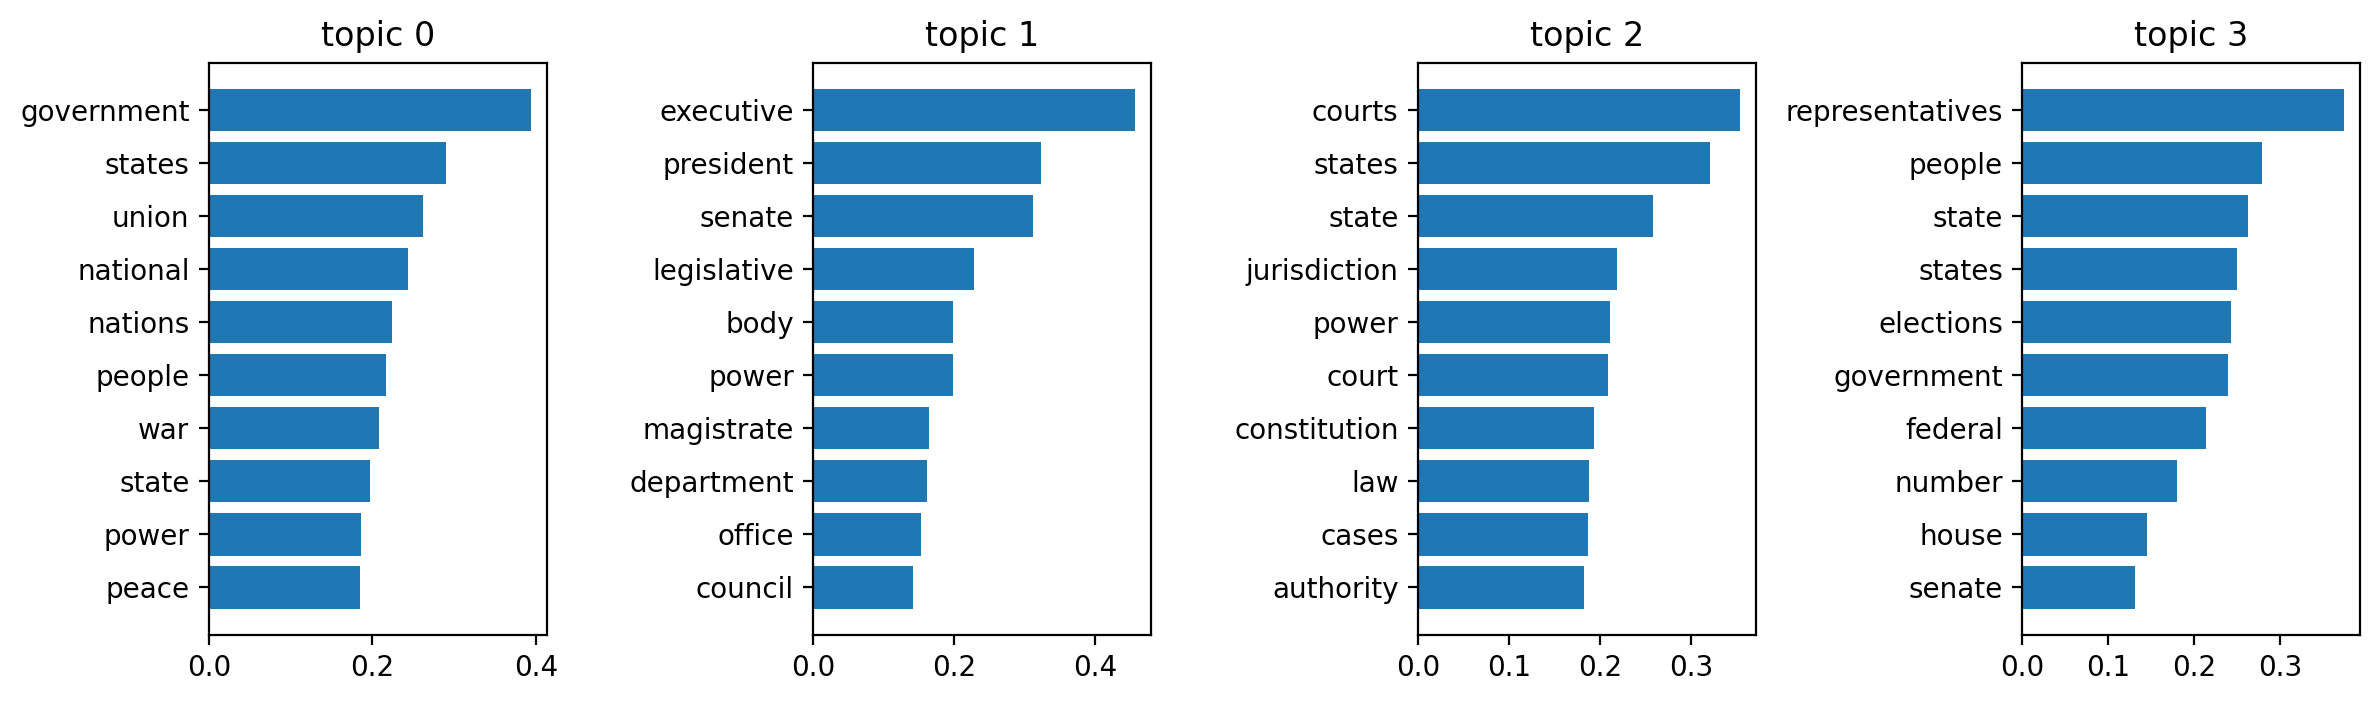

In [48]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.6))
for k, ax in enumerate(axes):
    row = nmf.components_[k]
    top = row.argsort()[::-1][:10]
    ax.barh(terms[top][::-1], row[top][::-1])
    ax.set_title(f'topic {k}')
fig.tight_layout()
plt.show()

### Each essay's topic weights, in the order of publication

Turn each essay's four weights into shares, and stack them by essay
number.

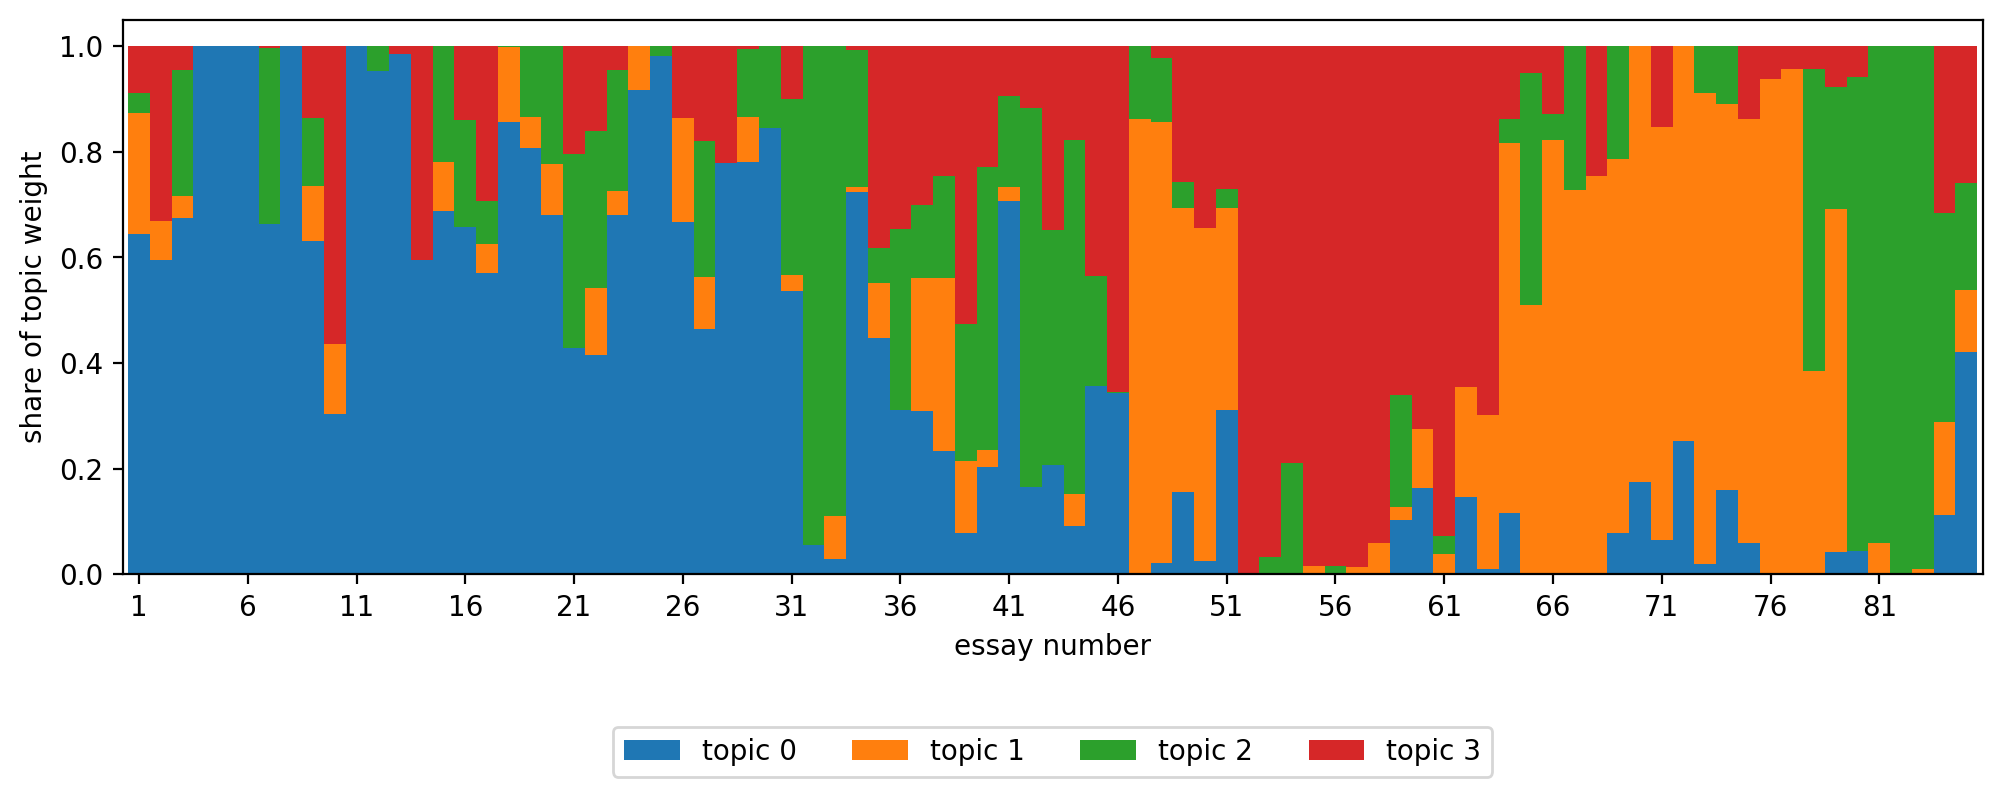

In [49]:
shares = pd.DataFrame(weights / weights.sum(axis=1, keepdims=True),
                      index=essays['essay'],
                      columns=[f'topic {k}' for k in range(4)])
ax = shares.plot.bar(stacked=True, width=1, figsize=(12, 3.6))
ax.set(xlabel='essay number', ylabel='share of topic weight')
ax.set_xticks(range(0, 85, 5))
ax.set_xticklabels(range(1, 86, 5), rotation=0)
ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.25))
plt.show()

- The topics come in blocks. Topic 0 fills most of essays 1 to 36 (the union, the
  defects of the confederation, taxation and defense); topic 3 runs
  through 52 to 61 (the House); topic 1 from 65 to 77 (the executive);
  topic 2 from 78 (the judiciary).
- Publius wrote the essays in the order of the Constitution's articles.
  The model found that order from word counts alone.

### Which topic does each author's essays fall in?

Give each essay its largest topic, and cross it with the author.

In [50]:
essays['topic'] = weights.argmax(axis=1)
pd.crosstab(essays['author'], essays['topic'])

topic,0,1,2,3
author,,,,
Disputed,0,3,0,9
Hamilton,25,14,8,4
Jay,4,1,0,0
Joint,3,0,0,0
Madison,3,3,4,4


- 9 of the 12 disputed essays sit in topic 3, the House and elections. So
  do 4 of Madison's essays, and 4 of Hamilton's.

### ❓ Question

Does the crosstab show that Madison wrote the disputed essays?

<details><summary>Answer</summary>

**No.** A topic says what an essay is about. Hamilton has 4 essays in the
same topic, so being about the House does not make an essay Madison's.
Topics measure subject. Authorship needed the style words of Part 2.

</details>

### Choices that move the result

The number of topics is the analyst's choice. Fit three and six, and read
the words.

In [51]:
for k in [3, 6]:
    model = NMF(n_components=k, random_state=0, max_iter=1000)
    model.fit(tfidf)
    for j, row in enumerate(model.components_):
        print(k, j, ', '.join(terms[row.argsort()[::-1][:6]]))

3 0 government, states, state, people, national, union
3 1 executive, senate, president, legislative, body, power
3 2 courts, states, court, jurisdiction, state, jury
6 0 states, state, power, government, union, powers
6 1 executive, legislative, department, departments, judiciary, council
6 2 courts, court, jury, jurisdiction, cases, causes
6 3 representatives, people, elections, state, government, states
6 4 president, senate, body, treaties, power, nomination
6 5 nations, government, war, military, peace, people


- Three topics fold the House into the union topic. Six split the
  executive into the departments and the president's treaty power, and
  separate war and the military from the union.
- Other choices move the result too: `random_state` (the starting point),
  the stop-word list, and `min_df`. Fit several settings, read the words,
  keep the fit whose topics you can name and use, and report the settings.

### LDA: a probabilistic topic model

Latent Dirichlet allocation (Blei, Ng, and Jordan 2003,
[*JMLR*](https://www.jmlr.org/papers/v3/blei03a.html)) treats each
document as a mixture of topics and each topic as a probability
distribution over words. It models counts, so it takes the count matrix,
not tf-idf
([docs](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.LatentDirichletAllocation.html)).

In [52]:
lda = LatentDirichletAllocation(n_components=4, random_state=0)
doc_topics = lda.fit_transform(counts)
for k, row in enumerate(lda.components_):
    print(k, ', '.join(terms[row.argsort()[::-1][:8]]))

0 states, state, courts, cases, constitution, convention, law, government
1 people, executive, power, senate, government, body, legislative, constitution
2 states, government, state, power, people, constitution, union, federal
3 government, union, war, states, nations, national, general, confederacy


- Each row of `doc_topics` sums to 1: the share of the essay in each
  topic. The themes overlap with NMF's, with blurrier word lists on 85
  documents.
- LDA is the standard for large corpora (thousands of documents). The
  `gensim` library ([docs](https://radimrehurek.com/gensim/)) fits it at
  scale, and `pyLDAvis`
  ([docs](https://github.com/bmabey/pyLDAvis)) draws an interactive map
  of the topics.

### BERTopic: embeddings instead of counts

BERTopic (Grootendorst 2022, [arXiv](https://arxiv.org/abs/2203.05794);
[docs](https://maartengr.github.io/BERTopic/)) starts from a pretrained
language model that turns each document into a vector of meaning, not of
word counts. It then reduces the dimensions, clusters the documents, and
names each cluster by its distinctive words. The model download is large,
so the code is shown and not run here.

```python
from bertopic import BERTopic

topic_model = BERTopic(min_topic_size=5)
topics, probs = topic_model.fit_transform(essays['text'].tolist())
topic_model.get_topic_info()
```

- Two documents can land in one cluster without sharing a word, which
  fixes the synonym limit of counts.
- The result depends on the pretrained model and the clustering settings,
  and it is harder to audit word by word.

### Which topic model?

| Method | Input | Strengths | Weaknesses | Docs |
|---|---|---|---|---|
| NMF | tf-idf or counts | fast; clean word lists on small corpora; easy to read as $W H$ | no probability model; the number of topics is a guess | [sklearn](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.NMF.html) |
| LDA | counts | a probability model; the standard for large corpora; many extensions | slower; blurry on small corpora; runs differ by seed | [sklearn](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.LatentDirichletAllocation.html), [gensim](https://radimrehurek.com/gensim/) |
| STM | counts plus covariates | lets topic shares depend on author, date, or party; built for social science | R only (`stm`) | [structuraltopicmodel.com](https://www.structuraltopicmodel.com/) |
| BERTopic | embeddings | handles synonyms and short texts; good on social media | large model download; harder to audit; settings matter | [BERTopic](https://maartengr.github.io/BERTopic/) |

Whatever the method: read the top words, read a few documents from each
topic, refit with other settings, and report the settings with the
result.

## What these tools are for

- A **document-term matrix** turns a corpus into rows of numbers that any
  method can use: counts for what is said, tf-idf for what is distinctive.
- **Cosine similarity** finds the documents that are alike: nearest
  essays, duplicate news stories, similar job ads.
- **Topic models** summarize a corpus too large to read: Quinn and
  co-authors (2010) tracked what the U.S. Senate talked about over
  eight years from 118,000 speeches; Roberts and co-authors (2014) sorted
  open-ended survey answers. Grimmer and Stewart (2013) review the field.
- The representation is a measurement choice. The stop-word list that
  cleans a topic model destroys an authorship test. Choose the columns for
  the question.

Grimmer, J., and B. M. Stewart (2013). "Text as Data." *Political
Analysis* 21(3): 267–297. [doi:10.1093/pan/mps028](https://doi.org/10.1093/pan/mps028).
Quinn, K. M., B. L. Monroe, M. Colaresi, M. H. Crespin, and D. R. Radev
(2010). "How to Analyze Political Attention with Minimal Assumptions and
Costs." *American Journal of Political Science* 54(1): 209–228.

### What we learned: functions and methods

| Goal | Write |
|---|---|
| Count words, one row per document | `CountVectorizer().fit_transform(texts)` |
| Drop common words; drop rare words | `stop_words='english'`; `min_df=2` |
| Count a fixed list of words | `CountVectorizer(vocabulary=[...])` |
| Name the columns | `.get_feature_names_out()` |
| Weight words by document and corpus | `TfidfVectorizer(...).fit_transform(texts)` |
| Compare every pair of rows | `cosine_similarity(matrix)` |
| Fit topics; read them | `NMF(n_components=k).fit_transform(matrix)`; `.components_` |
| Largest topic per document | `weights.argmax(axis=1)` |
| A probabilistic topic model | `LatentDirichletAllocation(n_components=k)` |

## Activity: who wrote more of the joint essays?

Essays 18, 19, and 20 compare the Constitution with ancient and modern
confederacies. Hamilton and Madison wrote them together. The activity
notebook asks which author's hand shows more in each, with the tools of
today:

1. The five nearest essays of each joint essay, with their authors.
2. Each joint essay's mean similarity to Hamilton's and to Madison's
   essays.
3. The counts and rates of `upon`, `whilst`, `while`, and `on` in the
   three essays.
4. The topic each essay falls in, and why the topic cannot decide the
   question.
5. A claim about each essay, and why a single-author answer is wrong by
   construction.